# 05 · Reserve uncertainty: Mack and bootstrap

**Question this notebook answers:** how uncertain is the reserve, and what do the standard stochastic models miss?

Two standard approaches, both written from scratch in `src/reserving/uncertainty.py` and tested against the published Taylor-Ashe figures (Mack 1993) and the `chainladder` package:

* **Mack (1993):** a distribution-free model of the chain ladder giving analytic standard errors, split into *process* error (randomness of future claims) and *parameter* error (uncertainty in the estimated factors).
* **ODP bootstrap (England & Verrall, 2002):** resample the residuals of the over-dispersed Poisson chain ladder to create thousands of pseudo-triangles, re-fit each, and simulate future payments. It gives a full distribution, hence percentiles.

> **Pensions analogy.** This is the reserving equivalent of moving from a best-estimate liability to a stressed one, like a longevity or interest-rate stress in BPA pricing. The capital and risk-margin frameworks (Solvency II SCR at 99.5%, IFRS 17 risk adjustment at a chosen confidence level) need exactly this kind of distribution.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from reserving import config as cfg, data as D, plots as PL

PL.setup()
pd.options.display.float_format = "{:,.3f}".format
pd.options.display.width = 140

In [2]:
from reserving.uncertainty import mack, odp_bootstrap
from reserving.diagnostics import pearson_residuals

df = D.load_cas()
co = D.company(df, cfg.STUDY_GRCODE)
paid, case = co.paid, co.case
paid_latest = paid.latest_diagonal()

## 1. Mack standard errors

Mack is applied to the chain ladder **without** the small tail factor (Mack's formulae cover the observed development; the 0.5% / 0.2% tails are deterministic loadings and don't change the conclusions).

For case incurred, Mack's "reserve" is ultimate − case incurred (the IBNR on top of case reserves). Its standard error describes uncertainty in the **ultimate**, so it applies equally to the unpaid amount.

In [3]:
m_paid, m_case = mack(paid), mack(case)
def mack_tbl(m, basis):
    t = m.table[["reserve", "process_se", "parameter_se", "mack_se", "cv"]].copy()
    t.loc["Total"] = [m.total_reserve, np.nan, np.nan, m.total_se, m.total_cv]
    return t
print("Mack on PAID (reserve = unpaid)")
display(mack_tbl(m_paid, "paid").style.format({"reserve": "{:,.0f}", "process_se": "{:,.0f}", "parameter_se": "{:,.0f}", "mack_se": "{:,.0f}", "cv": "{:.1%}"}, na_rep=""))
print("Mack on CASE INCURRED (reserve = IBNR over case)")
display(mack_tbl(m_case, "case").style.format({"reserve": "{:,.0f}", "process_se": "{:,.0f}", "parameter_se": "{:,.0f}", "mack_se": "{:,.0f}", "cv": "{:.1%}"}, na_rep=""))

Mack on PAID (reserve = unpaid)


,reserve,process_se,parameter_se,mack_se,cv
origin,,,,,
1988,0,0,0,0,
1989,6,123,127,176,2741.6%
1990,175,185,166,248,142.2%
1991,426,208,145,253,59.5%
1992,"1,384",515,291,592,42.8%
1993,"3,270",667,412,784,24.0%
1994,"9,043","1,668",947,"1,918",21.2%
1995,"16,434","1,997","1,077","2,269",13.8%
1996,"23,667","2,980","1,365","3,278",13.8%


Mack on CASE INCURRED (reserve = IBNR over case)


,reserve,process_se,parameter_se,mack_se,cv
origin,,,,,
1988,0,0,0,0,
1989,9,74,77,106,1237.2%
1990,2,114,101,152,7878.2%
1991,151,121,87,150,98.9%
1992,224,184,119,219,97.8%
1993,424,718,383,814,191.8%
1994,"1,841","1,569",841,"1,780",96.7%
1995,"4,258","1,813",921,"2,033",47.7%
1996,"8,099","2,462","1,078","2,687",33.2%


In [4]:
cl_case_unpaid = (m_case.table["ultimate"] - paid_latest).sum()
summ = pd.DataFrame({
    "CL unpaid": [m_paid.total_reserve, cl_case_unpaid],
    "Mack s.e.": [m_paid.total_se, m_case.total_se],
}, index=["paid", "case incurred"])
summ["CV of unpaid"] = summ["Mack s.e."] / summ["CL unpaid"]
summ.style.format({"CL unpaid": "{:,.0f}", "Mack s.e.": "{:,.0f}", "CV of unpaid": "{:.1%}"})

,CL unpaid,Mack s.e.,CV of unpaid
paid,"88,272","7,615",8.6%
case incurred,"68,548","5,997",8.7%


Both bases give a CV of about **9%** of the unpaid amount. As always with Mack, the CV is small for mature years (little left to develop) and large for the latest year (one observed point, multiplied by a large CDF). CVs for the oldest years are meaningless because their reserves are close to zero.

## 2. ODP bootstrap

First, a check of the model's assumptions. The bootstrap resamples residuals, so they should look roughly identically distributed across development ages, without strong structure.

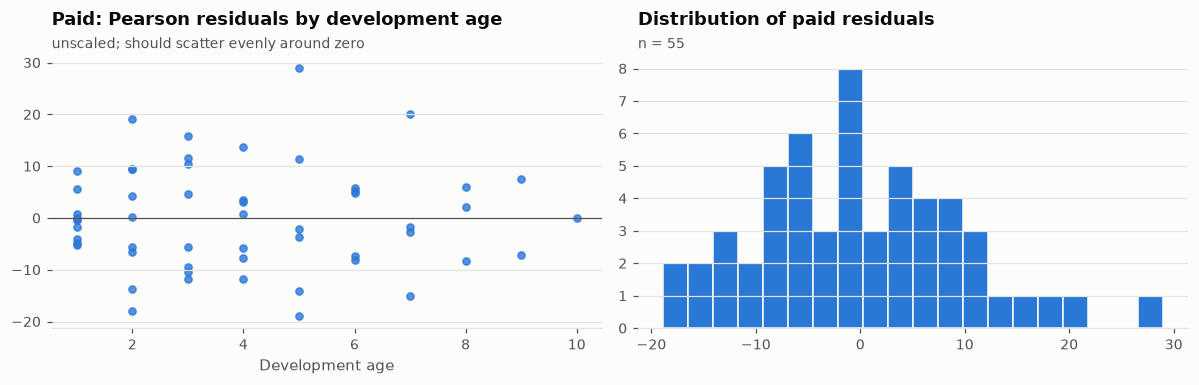

In [5]:
res_p = pearson_residuals(paid)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
for age in res_p.columns:
    v = res_p[age].dropna()
    ax.scatter([age] * len(v), v, color=PL.SERIES[0], s=22, alpha=0.8)
ax.axhline(0, color=PL.INK_2, lw=0.8)
ax.set_title("Paid: Pearson residuals by development age")
PL.subtitle(ax, "unscaled; should scatter evenly around zero")
ax.set_xlabel("Development age")
ax = axes[1]
vals = res_p.stack().dropna()
ax.hist(vals, bins=20, color=PL.SERIES[0], edgecolor=PL.SURFACE)
ax.set_title("Distribution of paid residuals")
PL.subtitle(ax, f"n = {len(vals)}")
fig.tight_layout()
PL.save(fig, "05_bootstrap_residuals")
plt.show()

No strong pattern by age, and a roughly symmetric distribution. The spread is somewhat wider at early ages, which is common and acceptable for a standard bootstrap. A refinement would scale residuals by age (heteroscedasticity adjustment), noted as a possible extension.

Now 10,000 simulations on each basis:

In [6]:
boot_p = odp_bootstrap(paid, n_sims=cfg.N_BOOTSTRAP, seed=cfg.SEED)
boot_c = odp_bootstrap(case, n_sims=cfg.N_BOOTSTRAP, seed=cfg.SEED)
# case bootstrap simulates IBNR over case incurred; convert to unpaid
case_os = (case.latest_diagonal() - paid_latest).sum()
tot_p = boot_p.total
tot_c = boot_c.total + case_os

def pct_row(x):
    return pd.Series({"mean": x.mean(), "s.e.": x.std(), "CV": x.std() / x.mean(),
                      **{f"{q:g}th pct": np.quantile(x, q / 100) for q in [5, 25, 50, 75, 95, 99.5]}})
bt = pd.DataFrame({"paid bootstrap": pct_row(tot_p), "case bootstrap": pct_row(tot_c)}).T
bt.style.format("{:,.0f}").format("{:.1%}", subset=["CV"])

,mean,s.e.,CV,5th pct,25th pct,50th pct,75th pct,95th pct,99.5th pct
paid bootstrap,"88,471","7,523",8.5%,"76,607","83,242","88,244","93,359","101,346","109,180"
case bootstrap,"68,495","7,732",11.3%,"56,615","63,054","68,008","73,362","82,051","91,108"


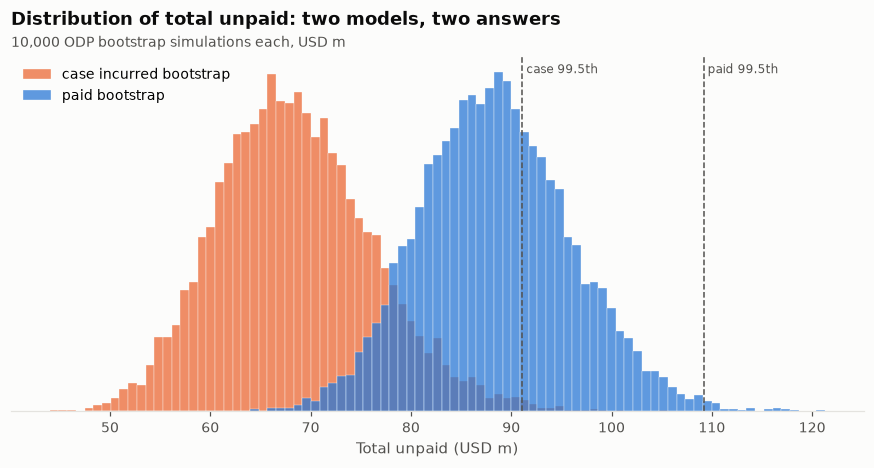

Share of paid simulations below the case-bootstrap median: 0.17%


In [7]:
fig, ax = plt.subplots(figsize=(10, 4.2))
bins = np.linspace(min(tot_p.min(), tot_c.min()), max(tot_p.max(), tot_c.max()), 90) / 1e3
ax.hist(tot_c / 1e3, bins=bins, color=PL.COLOURS["CL case"], alpha=0.75, label="case incurred bootstrap", edgecolor=PL.SURFACE, linewidth=0.3)
ax.hist(tot_p / 1e3, bins=bins, color=PL.COLOURS["CL paid"], alpha=0.75, label="paid bootstrap", edgecolor=PL.SURFACE, linewidth=0.3)
for x, lab in [(np.quantile(tot_p, 0.995), "paid 99.5th"), (np.quantile(tot_c, 0.995), "case 99.5th")]:
    ax.axvline(x / 1e3, color=PL.INK_2, lw=1, ls="--")
    ax.text(x / 1e3, ax.get_ylim()[1] * 0.95, f" {lab}", fontsize=8, color=PL.INK_2)
ax.set_title("Distribution of total unpaid: two models, two answers")
PL.subtitle(ax, "10,000 ODP bootstrap simulations each, USD m")
ax.set_xlabel("Total unpaid (USD m)")
ax.set_yticks([])
ax.grid(False)
ax.legend(loc="upper left")
PL.save(fig, "05_bootstrap_paid_vs_case")
plt.show()
print(f"Share of paid simulations below the case-bootstrap median: {np.mean(tot_p < np.median(tot_c)):.2%}")

## 3. The real lesson: model error dominates

This chart is the most important result in the notebook. **Each model is confident (CV 9-11%), and the two barely overlap.** The case bootstrap's median sits below almost the entire paid distribution.

Mack and the bootstrap measure **process** and **parameter** risk *within* a model. They are silent on **model risk**: the possibility that the model itself is wrong, for example because settlement speeds or case strength changed (notebook 02). Here, the uncertainty about *which model to believe* (~$20m) is about **2.5× the s.e. of either model**.

So for this company:

* the stochastic output is a **lower bound** on true uncertainty
* the range around the selected reserve should come from the stochastic CV **plus** judgement about the method spread, not from one bootstrap
* the most valuable work isn't more simulation but resolving the paid vs case question, with claim counts in a real review and back-testing here (notebook 06)

This is also why actuarial standards (e.g. the UK's TAS 100 / TAS 200, and the IFoA's work on reserving uncertainty) emphasise communicating the limitations of stochastic models alongside their output.

## 4. Range around the selected reserve

The selected reserve (notebook 08) blends paid and case methods. For its range I use the **case-basis Mack CV** (~9%, the more informative basis) with a lognormal shape (non-negative, right-skewed), centred on the selected value. The pipeline computes this so the report and README use identical figures:

In [8]:
from reserving.pipeline import run
rev = run(n_sims=2000)
p = rev.extras["selected_percentiles"]
sel = rev.selected["selected_unpaid"].sum()
pd.Series({"selected (mean)": sel, "25th pct": p[0.25], "median": p[0.5], "75th pct": p[0.75], "95th pct": p[0.95], "99.5th pct": p[0.995],
           "CV": rev.extras["selected_cv"]}).to_frame("USD 000").style.format("{:,.3f}", subset=pd.IndexSlice[["CV"], :]).format("{:,.0f}", subset=pd.IndexSlice[["selected (mean)", "25th pct", "median", "75th pct", "95th pct", "99.5th pct"], :])

,USD 000
selected (mean),"70,522"
25th pct,"66,279"
median,"70,259"
75th pct,"74,478"
95th pct,"80,995"
99.5th pct,"87,784"
CV,0.087


The case CL result ($69m) sits comfortably inside this range, but the paid CL result ($90m) lies **above even its 99.5th percentile**. The range answers "how much could the outcome vary if the selected model is right?" The paid/case spread answers "how wrong could the model be?" A full reserve report presents both.

## Conclusions → next steps

* **Mack and bootstrap broadly agree:** CV ≈ 9-11% on either basis. Both implementations validate against published results (see `tests/`).
* **Model risk is bigger than statistical risk:** the paid and case bootstraps barely overlap. Stochastic ranges here are a lower bound.
* Notebook 06 uses hindsight to settle which model was right, and builds evidence for weighting methods by maturity.